# PCA weights on stock returns

The subject is the eigendecomposition of the correlation matrix of standardized daily equity returns.
The eigenvectors are the weights, also called loadings: component k is the combination
`PC_k = w_1k x_1 + ... + w_pk x_p`, where each weight vector has length 1 and sits at right angles to
every other weight vector.

The conventional reading assigns component 1 to a market factor, meaning all securities move together;
component 2 to a spread, meaning one group of securities moves against another; and components 3 onward
to sector-specific structure. This notebook tests that reading against the price history in the project
database.

It also applies three procedures from López de Prado, *Machine Learning for Asset Managers* (2020),
chapter 2. Denoising rebuilds the correlation matrix with the eigenvalues attributable to sampling error
flattened to a common value. Detoning rebuilds it with the market component removed. An eigenportfolio
converts a component's weights into holdings that could be traded. Each is defined in the section that
uses it, sections 7 and 8.

The code sits in three files in `notebooks/`. `eigen.py` holds the mathematics and accepts only
matrices, with no database access, so it can be tested against cases whose answers are known in closed
form. `panels.py` holds every DuckDB query. `helpers.py` holds the plotting functions. The tests are
`tests/test_eigen.py` and `tests/test_panels.py`.

In [14]:
%load_ext autoreload
%autoreload 2
import eigen
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import panels
from helpers import (
    connect_readonly,
    plot_corr_heatmap,
    plot_loadings,
    plot_mp_fit,
    plot_scree,
    plot_sector_means,
    plot_stability,
    sector_order,
    show_df,
    show_note,
)

from investalyze.apps import universes

plt.rcParams['figure.dpi'] = 130
con = connect_readonly()
print('saved universes available:', universes.list_universes())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


saved universes available: ['0_to_check', 'BL_shell_companies', 'BL_unknown_sector', 'mid_large_mega_non_fin_realest', 'solar_small_mid_large']


## Parameters

Every setting is in the cell below. Changing one requires re-running from that cell downward.

### Which securities enter the cross-section

The default is the `N_TOP` securities with the highest turnover that also have an unbroken price history
across the sample period. Turnover here means the median over the window of closing price times daily
volume, which is the money that changed hands in the security on a typical session.

Turnover is the default for one reason. A security that does not trade on a given session has no new
price, so the previous close is carried forward. The panel then sees two identical closes and records a
return of exactly zero. That zero is not a measurement: it says the security did not move, when what
happened is that it did not trade. Such zeros pull correlation estimates toward zero, and correlation is
the only quantity this notebook measures. Over the five years to 2026-08 the 400 highest-turnover
securities show a carried-forward close on 0.24% of sessions. The least traded third show one on 5.03%
of sessions, twenty times as often.

The default is not binding. `RANK_BY = 'mcap'` ranks by market capitalization instead, which is share
count times share price. At `N_TOP = 400` the two rankings select 298 of the same securities out of 400.
`UNIVERSE` accepts the name of a saved selection, stored as a CSV file in `data/universes/`, or a list of
tickers written out directly. Anything supplied that way is still filtered for unbroken history, because
a gap breaks the return differencing described in section 2.

### How long the sample must be

Write N for the number of securities and T for the number of trading sessions.

The correlation matrix contains N(N-1)/2 distinct pairs, which is 79,800 pairs at N = 400, and every one
of them is estimated from T observations. As N approaches T those estimates come to be dominated by
sampling error. Once N exceeds T the sample correlation matrix is singular, meaning some of its
eigenvalues are exactly zero and the matrix cannot be inverted. Sections 3 and 7 return numbers in that
situation rather than raising an error, so the condition is checked here instead.

The ratio T/N should be well above 1. At least 2 is a defensible minimum, which at N = 400 requires 800
sessions, or roughly three years. Section 2 prints N, T and their ratio, and stops if T does not
exceed N.

In [15]:
START       = '2010-08-01'  # first session of the panel; None starts at the earliest available
END         = None          # last session of the panel; None ends at the most recent available

UNIVERSE    = None          # which securities to consider. None searches the whole database. A string
                            # names a saved selection in data/universes/, e.g. 'mid_large_mega_non_fin_realest'.
                            # A list names them directly, e.g. ['AAPL', 'MSFT', 'XOM'].
RANK_BY     = 'liquidity'   # how to choose when more securities qualify than N_TOP allows.
                            # 'liquidity' = highest turnover, 'mcap' = largest market capitalization,
                            # 'ticker' = alphabetical, i.e. no preference at all.
N_TOP       = 400           # how many securities to keep. None keeps every one that qualifies.

RETURN_KIND = 'log'         # 'log' has better statistical behaviour for estimation. 'simple' is what a
                            # portfolio return is a weighted sum of. Section 8 uses 'simple' regardless.
BENCHMARK   = '^NDX'        # index PC1 is compared against in section 4. '^NDX' is the Nasdaq-100 and
                            # '^NDQ' the Nasdaq Composite; both run to the present. '^SPX', the S&P 500,
                            # stops at 2026-07-02 and would cover only part of a recent window.
N_SHOW      = 10            # how many components to examine individually in sections 4 to 6.
ROLL_WINDOW = 504           # length in sessions of the moving window section 9 refits on. 504 is 2 years.
ROLL_STEP   = 21            # how many sessions that window advances between refits. 21 is about 1 month.

## 1. Toy example

The procedure is run first on invented data: three securities, named A, B and C, observed over eight
consecutive trading days. At that size every intermediate table can be read in full. The section calls
the same functions as the real panel in section 2, so it doubles as a record of what each stage
produces.

The stages are:

    closing prices -> daily returns -> standardized returns -> correlation matrix -> eigenvectors

Two of them need justifying.

**Returns rather than prices.** A price series is non-stationary, meaning its average level in one
period differs from its average level in another because the price drifts. Decomposing prices directly
would produce a first component that measures little more than how much each security appreciated over
the sample, which says nothing about which securities move together. Taking returns, that is the change
from each session to the next, removes the level and leaves the daily movements.

**Standardized rather than raw returns.** Standardizing a series means subtracting its mean and dividing
by its standard deviation, leaving it with mean 0 and standard deviation 1. Without that step the
decomposition is dominated by whichever securities happen to be most volatile, because their larger
variances sit in the matrix being decomposed. With it, the covariance matrix of the transformed data is
exactly the correlation matrix of the original data, so the components describe how securities move
together rather than which of them moves most.

In [16]:
toy_closes = pd.DataFrame(
    {'A': [100.00, 100.50, 100.50, 102.01, 102.52, 103.54, 101.99, 104.54],
     'B': [50.00, 50.25, 50.00, 51.00, 51.51, 52.28, 51.76, 52.28],
     'C': [20.00, 19.90, 19.70, 19.70, 20.10, 19.99, 19.89, 20.09]},
    index=pd.bdate_range('2024-01-02', periods=8, name='Date'))

toy_returns = panels.returns_panel(toy_closes, kind='log')
toy_std = panels.standardize(toy_returns)
toy_corr = eigen.correlation(toy_std.z)
toy_eig = eigen.eigen_decompose(toy_corr)

show_note('Closing prices. Three securities, one price per trading day, eight days.')
show_df(toy_closes, decimals=2)

show_note('Daily log returns, in percent. Each is one session against the one before, so eight prices '
          'give seven returns. The price level is gone.')
show_df(toy_returns * 100, decimals=2)

show_note('The same returns, standardized. Every column now has mean 0 and standard deviation 1.')
show_df(toy_std.z, decimals=4)

show_note('Correlation matrix of the standardized returns. A and B correlate at 0.80, and each of them '
          'correlates near 0.40 with C. This matrix is what gets decomposed.')
show_df(toy_corr, decimals=4)

show_note('Eigenvalues, largest first, with the share of the total variance each one accounts for.')
show_df(pd.DataFrame({'eigenvalue': toy_eig.values,
                      'share of variance': eigen.variance_explained(toy_eig.values)},
                     index=['PC1', 'PC2', 'PC3']), decimals=4)

show_note('Eigenvectors: the weights. One column per component, one row per security. Every column has '
          'length 1, and any two columns are at right angles.')
show_df(eigen.loadings_frame(toy_eig), decimals=4)

print(f'eigenvalues sum to {toy_eig.values.sum():.10f}   (with 3 securities the sum must be exactly 3)')

*Closing prices. Three securities, one price per trading day, eight days.*

,A,B,C
Date,,,
2024-01-02 00:00:00,100,50,20
2024-01-03 00:00:00,100.5,50.25,19.9
2024-01-04 00:00:00,100.5,50,19.7
2024-01-05 00:00:00,102.01,51,19.7
2024-01-08 00:00:00,102.52,51.51,20.1
2024-01-09 00:00:00,103.54,52.28,19.99
2024-01-10 00:00:00,101.99,51.76,19.89
2024-01-11 00:00:00,104.54,52.28,20.09


*Daily log returns, in percent. Each is one session against the one before, so eight prices give seven returns. The price level is gone.*

,A,B,C
Date,,,
2024-01-03 00:00:00,0.4988,0.4988,-0.5013
2024-01-04 00:00:00,0,-0.4988,-1.0101
2024-01-05 00:00:00,1.4913,1.9803,0
2024-01-08 00:00:00,0.4987,0.995,2.0101
2024-01-09 00:00:00,0.99,1.4838,-0.5488
2024-01-10 00:00:00,-1.5083,-0.9996,-0.5015
2024-01-11 00:00:00,2.4695,0.9996,1.0005


*The same returns, standardized. Every column now has mean 0 and standard deviation 1.*

...

*Eigenvalues, largest first, with the share of the total variance each one accounts for.*

,eigenvalue,share of variance
PC1,2.0832,0.6944
PC2,0.7146,0.2382
PC3,0.2022,0.06742


*Eigenvectors: the weights. One column per component, one row per security. Every column has length 1, and any two columns are at right angles.*

,PC1,PC2,PC3
A,0.6298,-0.3179,0.7088
B,0.6284,-0.328,-0.7054
C,0.4567,0.8896,-0.006803


eigenvalues sum to 3.0000000000   (with 3 securities the sum must be exactly 3)


The three weight columns read as follows.

**PC1**, `(0.63, 0.63, 0.46)`. Every weight is positive and the three are of similar size, so the
component moves all three securities in the same direction at once. It accounts for 69% of the
variance, against 24% for PC2 and 7% for PC3. This is the market factor.

**PC2**, `(-0.32, -0.33, 0.89)`. C carries the opposite sign to A and B. The three weights sum to
approximately zero, so the component holds no net position in the market and instead expresses a
relative-value trade: long C, short the correlated pair.

**PC3**, `(0.71, -0.71, -0.01)`. A against B, with a weight on C small enough to ignore. This is the
most localized structure three securities allow.

The order market, spread, local matches the reading stated at the top of the notebook, but it does so
because the returns were invented to produce it. Whether the same order appears in real data is what
sections 4 to 6 examine, and section 9 tests whether the components past the first are stable enough for
any reading of them to mean anything.

The arithmetic is checked against a case with a known closed-form answer in `tests/test_eigen.py`.

## 2. Panel

A cross-sectional decomposition needs one set of dates common to every security, and the list of
distinct dates in the `prices` table does not supply one. That table contains sessions on which only a
handful of securities have a row. These are market holidays on which a few instruments report a price
anyway; 2026-06-19, Juneteenth, is one of them. If such a date joined the calendar, every security
without a price on it would be counted as having an incomplete history, and that is nearly all of them.

A session therefore joins the calendar only when the number of securities priced on it is large compared
with the sessions immediately around it. The comparison value is the median count over a window of 21
sessions centred on the date, and the session must reach `panels.MIN_DATE_COVERAGE` of that value. That
constant is defined at the top of `notebooks/panels.py` and is set to 0.5. A median is used rather than a
mean so that the holidays themselves do not drag the comparison value down.

The comparison is against neighbouring sessions rather than against the busiest session in the whole
window, and the distinction matters. The number of securities the table covers grows steadily over time.
A threshold measured against the largest session anywhere in the window would reject the earliest years
of a long window along with the holidays it is meant to remove, and would do so without saying anything.
The size of that growth over the window selected above is measured below.

Securities are then required to be priced on every session of the resulting calendar. Returns are
differenced along the calendar rather than along each security's own list of observed dates. A security
missing one session therefore yields two missing returns, instead of one return that covers two sessions
while being recorded as though it covered one.

In [17]:
calendar = panels.trading_calendar(con, start=START, end=END)

if UNIVERSE is None:
    candidates = None
elif isinstance(UNIVERSE, str):
    candidates = universes.load_universe(UNIVERSE)
else:
    candidates = list(UNIVERSE)

universe = panels.complete_universe(con, calendar, n_top=N_TOP, rank_by=RANK_BY, candidates=candidates)
closes   = panels.close_panel(con, universe, calendar)
returns  = panels.returns_panel(closes, kind=RETURN_KIND)
std      = panels.standardize(returns)
sectors  = panels.sector_labels(con, universe)

n_days, n_stocks = std.z.shape
days_per_stock = n_days / n_stocks
source = 'the whole database' if UNIVERSE is None else (UNIVERSE if isinstance(UNIVERSE, str) else f'{len(candidates)} named tickers')
print(f'requested window       {START or "earliest available"} to {END or "latest available"}')
print(f'calendar obtained      {calendar.min().date()} to {calendar.max().date()}')
print(f'securities (N)         {n_stocks}, selected by {RANK_BY} from {source}, spanning {sectors.nunique()} sectors')
print(f'trading sessions (T)   {n_days}, of which {int(std.z.isna().to_numpy().sum())} observations are missing')
print(f'ratio T/N              {days_per_stock:.2f}   (2.0 or above is the working minimum)')

if START is not None and calendar.min() > pd.Timestamp(START) + pd.Timedelta(days=10):
    show_note(f'The calendar begins {(calendar.min() - pd.Timestamp(START)).days} days after the requested START. '
              f'Sessions before {calendar.min().date()} did not meet the coverage threshold of '
              f'`panels.MIN_DATE_COVERAGE`, or no securities were priced on them.')
assert n_days > n_stocks, f'T = {n_days} does not exceed N = {n_stocks}: extend START, or reduce N_TOP'

requested window       2010-08-01 to latest available
calendar obtained      2010-08-02 to 2026-08-12
securities (N)         400, selected by liquidity from the whole database, spanning 11 sectors
trading sessions (T)   4031, of which 0 observations are missing
ratio T/N              10.08   (2.0 or above is the working minimum)


The panel is complete by construction, so no rule for filling missing values is needed and no invented
zero returns enter the correlation estimate.

The cell below measures what that completeness requirement costs. It separates the two reasons a
security can fail it. Starting its history after the window opened is the ordinary case of a security
that listed later, or of vendor coverage that begins later, and says nothing about data quality. A gap
inside a series that is otherwise present is the case that would matter, because it means observations
are missing for a security that existed throughout.

The same cell measures survivorship. A security whose listing ended part-way through the period would
show up as a series that stops before the window closes. The count of such series, and the dates on
which they stop, is what distinguishes a table that contains delisted companies from one that does not.

In [18]:
coverage = con.execute("""
    SELECT Ticker, min(Date) AS first_date, max(Date) AS last_date, count(*) AS sessions
    FROM prices
    WHERE AC IS NOT NULL AND AC > 0 AND Date IN (SELECT unnest(?::DATE[]))
    GROUP BY Ticker
""", [list(calendar.date)]).df()

opened, closed = calendar.min(), calendar.max()
spanning = coverage[(coverage['first_date'] <= opened) & (coverage['last_date'] >= closed)]
gap_free = int((spanning['sessions'] == len(calendar)).sum())

print(f'securities priced somewhere in the window   {len(coverage)}')
print(f'   first price after the window opened      {int((coverage["first_date"] > opened).sum())}   (listed later, or coverage begins later)')
print(f'   last price before the window closed      {int((coverage["last_date"] < closed).sum())}   (a delisting would appear here)')
print(f'   present at both ends                     {len(spanning)}')
if len(spanning) > 0:
    print(f'      priced on every session              {gap_free}   ({gap_free / len(spanning):.1%})')
    print(f'      carrying at least one gap            {len(spanning) - gap_free}')

show_note('Securities priced per session, by year. A growing count is why the calendar threshold is '
          'measured against nearby sessions rather than against the busiest session in the window.')
show_df(con.execute("""
    SELECT CAST(year(Date) AS VARCHAR) AS year,
           CAST(round(median(n)) AS BIGINT) AS "securities priced",
           count(*) AS sessions
    FROM (SELECT Date, count(*) AS n FROM prices
          WHERE AC IS NOT NULL AND AC > 0 AND Date IN (SELECT unnest(?::DATE[]))
          GROUP BY Date)
    GROUP BY 1 ORDER BY 1
""", [list(calendar.date)]).df().set_index('year'))

securities priced somewhere in the window   6431
   first price after the window opened      3816   (listed later, or coverage begins later)
   last price before the window closed      285   (a delisting would appear here)
   present at both ends                     2564
      priced on every session              2519   (98.2%)
      carrying at least one gap            45


*Securities priced per session, by year. A growing count is why the calendar threshold is measured against nearby sessions rather than against the busiest session in the window.*

,securities_priced,sessions
year,,
2010,"2,633",107
2011,"2,704",252
2012,"2,791",250
2013,"2,921",252
2014,"3,095",252
2015,"3,255.5",252
2016,"3,354",252
2017,"3,522",251
2018,"3,764",251


Read the count of series that stop early together with the dates on which they stop.

Series that stop only in the closing months of the window are ordinary recent delistings and
acquisitions. What matters is whether any stop earlier than that. A market loses a substantial fraction
of its listed companies to delisting, acquisition and bankruptcy over a period of years. A table
covering such a period with no series ending anywhere except at the very end is therefore not a record
of that market. It holds the securities that are listed today, with their history filled in backward,
and nothing else.

If that is the case here, survivorship is not imposed by the completeness filter in this notebook. It is
imposed by what was ingested into the database, and it cannot be relaxed by changing
`panels.MIN_DATE_COVERAGE` or by admitting securities with gaps. It sets a limit on what any long-window
result below can claim.

## 3. Spectrum

The eigenvalues computed from a finite sample are not the eigenvalues of the population the sample came
from. If N securities were completely unrelated, the population correlation matrix would have 1 on the
diagonal and 0 everywhere else, and all N of its eigenvalues would equal 1. A finite sample never
produces that. Sampling error spreads the eigenvalues out around 1. This section asks how many of the
observed eigenvalues are larger than that spreading alone can account for.

Write T for the number of trading sessions, N for the number of securities, and q for the ratio T/N. In
the code q is the variable `days_per_stock`, computed in section 2.

The Marcenko-Pastur theorem, a result in random matrix theory, gives the distribution those eigenvalues
follow when T independent observations are drawn on N unrelated series and both grow with q held fixed.
The distribution stops at a finite upper edge:

    lambda_max = sigma^2 (1 + sqrt(1/q))^2

sigma^2 is the share of total variance that is noise rather than genuine common movement. An eigenvalue
above lambda_max cannot be produced by sampling error alone, so it is read as marking real structure.
sigma^2 is not known in advance and has to be estimated from the observed eigenvalues.

Four criteria are reported rather than one. They are known to disagree, and the extent of their
disagreement is itself a result.

- **Marcenko-Pastur, kernel density fit.** The estimator López de Prado publishes. A kernel density
  estimate turns the list of observed eigenvalues into a smooth curve by placing a small bump over each
  one and adding them up. The width of those bumps is the bandwidth. sigma^2 is then chosen so that the
  theoretical density matches that curve as closely as possible. The answer depends on the bandwidth
  chosen, and the second cell below shows by how much.
- **Marcenko-Pastur, fixed point.** sigma^2 is required to equal the average of the eigenvalues that it
  classifies as noise. Starting from a guess and repeating until the value stops moving gives an
  estimate with no bandwidth in it at all.
- **Parallel analysis.** Each security's column of returns is shuffled in time, independently of the
  other columns. Shuffling destroys any relationship between securities while leaving each security's
  own distribution of returns untouched, so every eigenvalue the shuffled data produces is sampling
  error by construction. The largest one becomes the threshold.
- **Kaiser criterion.** Keep the components whose eigenvalue exceeds 1. The reasoning is that one
  standardized series contributes exactly 1 to the total, so a component below 1 explains less than a
  single security does.

In [19]:
corr = eigen.correlation(std.z)
eig  = eigen.eigen_decompose(corr)
explained = eigen.variance_explained(eig.values)

sigma2_kde = eigen.fit_sigma2(eig.values, q=days_per_stock)
sigma2_fix = eigen.fit_sigma2_iterative(eig.values, q=days_per_stock)
pa_edge    = eigen.parallel_analysis_threshold(std.z, n_trials=20, seed=0)

rows = []
for label, edge in [('Marcenko-Pastur, kernel density fit', eigen.max_noise_eigenvalue(q=days_per_stock, sigma2=sigma2_kde)),
                    ('Marcenko-Pastur, fixed point', eigen.max_noise_eigenvalue(q=days_per_stock, sigma2=sigma2_fix)),
                    ('Parallel analysis', pa_edge),
                    ('Kaiser, eigenvalue above 1', 1.0)]:
    rows.append({'criterion': label, 'noise edge': edge, 'components retained': int((eig.values > edge).sum())})
show_df(pd.DataFrame(rows).set_index('criterion'), decimals=4)
print(f'sigma^2 estimate            kernel density fit {sigma2_kde:.4f}, fixed point {sigma2_fix:.4f}')
print(f'share of variance, PC1 to PC5  {np.round(explained[:5] * 100, 2)}   cumulative {explained[:5].sum() * 100:.1f}%')

,noise edge,components retained
criterion,,
"Marcenko-Pastur, kernel density fit",1.7292,21
"Marcenko-Pastur, fixed point",0.3798,198
Parallel analysis,1.7353,21
"Kaiser, eigenvalue above 1",1,47


sigma^2 estimate            kernel density fit 1.0000, fixed point 0.2197
share of variance, PC1 to PC5  [34.04  4.85  3.32  2.1   1.77]   cumulative 46.1%


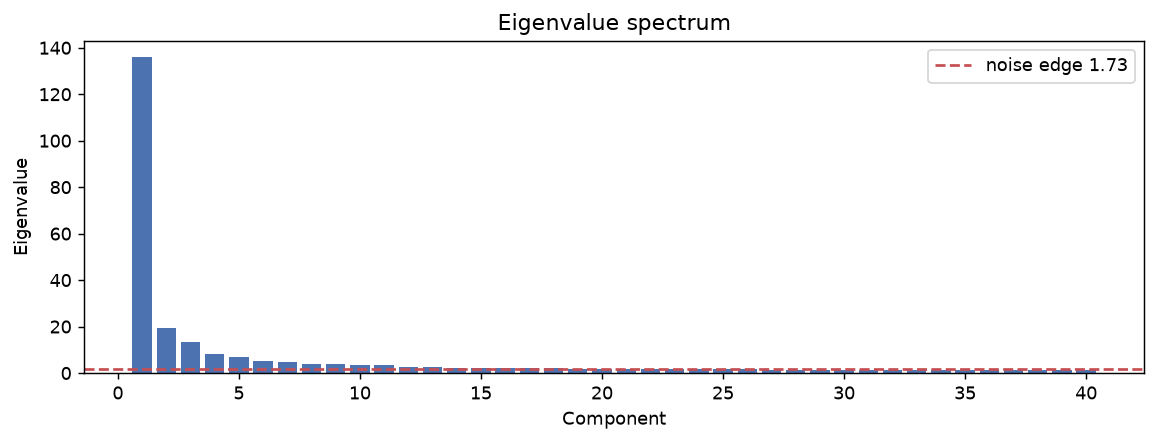

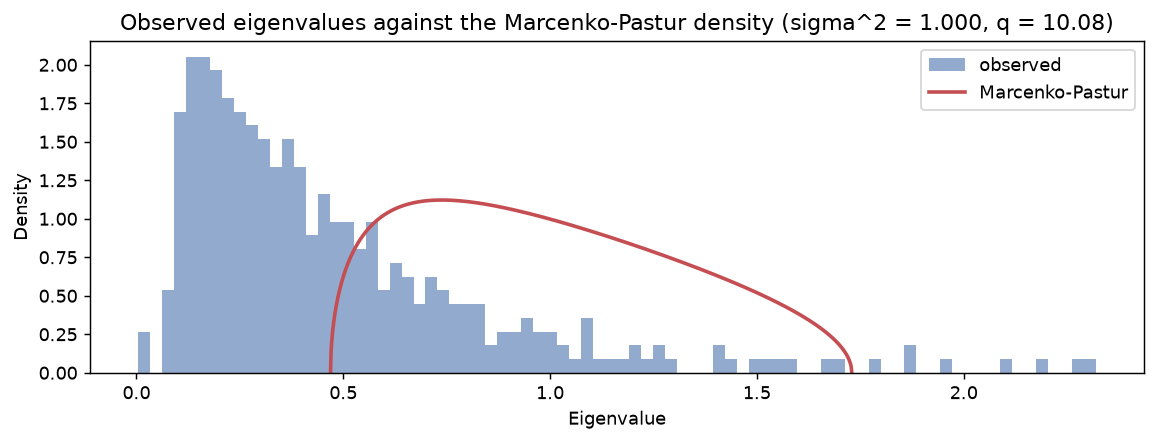

In [20]:
noise_edge = eigen.max_noise_eigenvalue(q=days_per_stock, sigma2=sigma2_kde)
plot_scree(eig.values, threshold=noise_edge, k=40)

support = np.linspace(eigen.min_noise_eigenvalue(q=days_per_stock, sigma2=sigma2_kde), noise_edge, 1000)
density = pd.Series(eigen.marcenko_pastur_pdf(support, q=days_per_stock, sigma2=sigma2_kde), index=support)
plot_mp_fit(eig.values, density,
            title=f'Observed eigenvalues against the Marcenko-Pastur density (sigma^2 = {sigma2_kde:.3f}, q = {days_per_stock:.2f})')

In [21]:
# Sensitivity of the kernel density estimate of sigma^2 to the choice of bandwidth
show_df(pd.DataFrame([
    {'bandwidth': bw,
     'sigma^2': (s := eigen.fit_sigma2(eig.values, q=days_per_stock, bandwidth=bw)),
     'noise edge': eigen.max_noise_eigenvalue(q=days_per_stock, sigma2=s),
     'components retained': eigen.n_signal_factors(eig.values, q=days_per_stock, sigma2=s)}
    for bw in (0.005, 0.01, 0.05, 0.1, 0.25, 0.5)]).set_index('bandwidth'), decimals=4)

,sigma2,noise edge,signal PCs
bandwidth,,,
0.005000,1,1.7292,21
0.010000,1,1.7292,21
0.050000,1,1.7292,21
0.100000,1,1.7292,21
0.250000,1,1.7292,21
0.500000,1,1.7292,21


The four criteria disagree, and the kernel density fit moves with its bandwidth. That is a property of
the data rather than a fault in the code.

The Marcenko-Pastur theorem assumes the observations are independent of one another, identically
distributed, and have a finite fourth moment. A finite fourth moment is a limit on how often extreme
values occur. Daily equity returns violate it: very large moves happen far more often than a normal
distribution allows. Equity returns are also heteroskedastic, meaning their volatility changes over
time, which breaks the identically-distributed assumption as well.

The consequence is visible in the eigenvalues. Their bulk has a long tail running down toward zero, and
no Marcenko-Pastur density reproduces that shape, so the position of its upper edge is poorly determined
whichever way sigma^2 is estimated.

The count of components carrying signal is therefore method-dependent, and no single number among them
should be relied on. Section 9 answers the question by a different route, asking how many components
reappear on data that was not used to compute them.

## 4. Is PC1 a market factor?

A market factor is a component that moves every security in the same direction at once. Three checks are
applied, because each of them can be passed for reasons other than the intended one.

1. Correlation between the PC1 time series and the returns of a broad index, named in `BENCHMARK`. The
   default is `^NDX`, the Nasdaq-100. A market factor should track it closely.
2. Correlation between the PC1 time series and the equal-weighted average of the standardized returns.
   This uses no data outside the panel, so unlike the first check it cannot be misled by an index that
   is stale or that covers a different set of securities than the panel does.
3. Homogeneity of the loadings, which is the proportion of them carrying the majority sign. A value near
   1 means the component pushes every security the same way; a value near 0.5 means it pushes half one
   way and half the other.

The sign of an eigenvector is arbitrary. It is fixed here by the convention that the largest loading in
absolute value is made positive, so the direction of the reported correlations follows from that
convention and carries no meaning by itself.

In [22]:
pcs = eigen.pc_series(std.z, eig, k=N_SHOW)
bench = panels.benchmark_returns(con, BENCHMARK, start=START, end=END, kind=RETURN_KIND)
joined = pcs.join(bench.rename('benchmark'), how='inner').dropna()
w1 = eigen.loadings_frame(eig)['PC1']

print(f'correlation with {BENCHMARK}            {joined["PC1"].corr(joined["benchmark"]):+.4f}   over {len(joined)} shared sessions')
print(f'correlation with the equal-weighted mean  {pcs["PC1"].corr(std.z.mean(axis=1)):+.4f}')
print(f'loading homogeneity                       {eigen.loading_homogeneity(w1):.4f}   (proportion carrying the majority sign)')
print(f'share of total variance                   {explained[0] * 100:.2f}%')
print(f'loading range                             {w1.min():.4f} to {w1.max():.4f}')

correlation with ^NDX            +0.8071   over 4031 shared sessions
correlation with the equal-weighted mean  +0.9991
loading homogeneity                       1.0000   (proportion carrying the majority sign)
share of total variance                   34.04%
loading range                             0.0148 to 0.0712


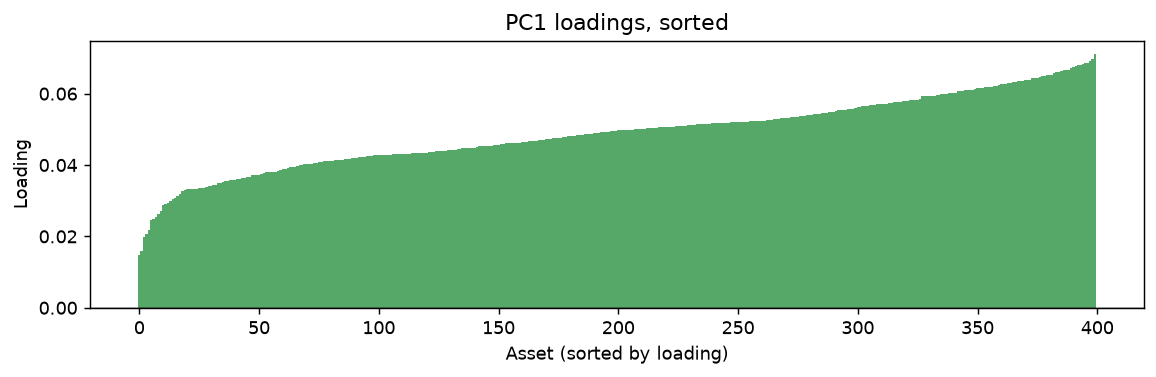

In [23]:
plot_loadings(w1, title='PC1 loadings, sorted')

## 5. Is PC2 a spread?

A relative-value factor holds offsetting long and short positions, so it carries little net exposure to
the market. Two properties are examined. The first is whether the loadings sum to approximately zero,
which is what makes the positions offsetting. The second is whether the securities at the two extremes
differ from each other in a way that can be recognised.

PC2 is at right angles to PC1 by construction, so that fact on its own is not evidence for the reading.
The question worth asking is whether the contrast PC2 draws has an economic interpretation, or whether
it is only the direction of largest remaining variance once the market has been taken out.

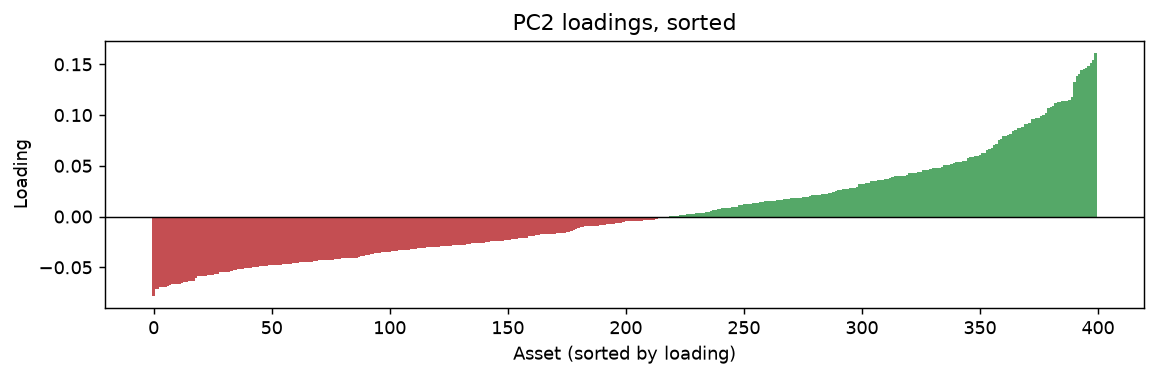

,loading,sector,side
Ticker,,,
ED,0.1612,Utilities,long
WEC,0.1542,Utilities,long
CMS,0.1512,Utilities,long
DUK,0.1488,Utilities,long
XEL,0.1467,Utilities,long
AEP,0.1452,Utilities,long
SO,0.1447,Utilities,long
AEE,0.1408,Utilities,long
ES,0.1381,Utilities,long


net loading         +1.2299   (zero would be exact market neutrality)
loading homogeneity 0.5475   (0.5 is an even long/short split)


In [24]:
w2 = eigen.loadings_frame(eig)['PC2']
plot_loadings(w2, title='PC2 loadings, sorted')

ends = pd.concat([w2.nlargest(10), w2.nsmallest(10)]).to_frame('loading')
ends['sector'] = sectors.reindex(ends.index)
ends['side'] = np.where(ends['loading'] > 0, 'long', 'short')
show_df(ends, decimals=4)
print(f'net loading         {w2.sum():+.4f}   (zero would be exact market neutrality)')
print(f'loading homogeneity {eigen.loading_homogeneity(w2):.4f}   (0.5 is an even long/short split)')

## 6. Sector structure

Whether a component reflects sector membership is tested by one-way analysis of variance on its
loadings, with securities grouped by the sector recorded for them in the `companies` table.

The statistic reported is eta squared. It is the share of the total variance of the loadings that lies
between sectors rather than within them. It is 0 when every sector has the same average loading, and 1
when every security in a sector has an identical loading.

Eta squared rises on its own as the number of groups rises and as sampling error rises, so its size
cannot be judged in isolation. Each value is therefore compared against a permutation null: the same
loadings are kept but the sector labels are shuffled at random, the statistic is recomputed, and this is
repeated many times to build a distribution of values that sector membership could produce by chance
alone. The 95th percentile of that distribution is reported beside the observed value. An observed value
below it is not evidence of sector structure.

In [25]:
eta = []
for name in [f'PC{i + 1}' for i in range(N_SHOW)]:
    loading = eigen.loadings_frame(eig)[name]
    observed = eigen.sector_eta_squared(loading, sectors)
    null95 = eigen.sector_eta_squared_null(loading, sectors, n_perm=200)
    eta.append({'component': name, 'eta^2': observed, 'permutation null 95%': null95,
                'above null': observed > null95})
eta = pd.DataFrame(eta).set_index('component')
show_df(eta, decimals=4)

,eta2,null 95%,above null
component,,,
PC1,0.416,0.04157,True
PC2,0.6112,0.04365,True
PC3,0.6681,0.04824,True
PC4,0.5575,0.04643,True
PC5,0.6156,0.04365,True
PC6,0.2818,0.04455,True
PC7,0.727,0.0475,True
PC8,0.4868,0.04766,True
PC9,0.4483,0.04525,True


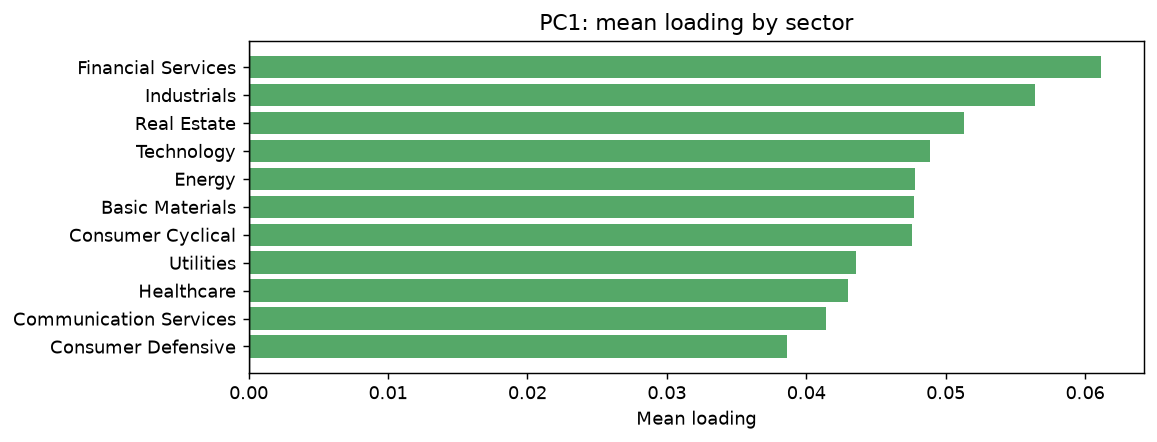

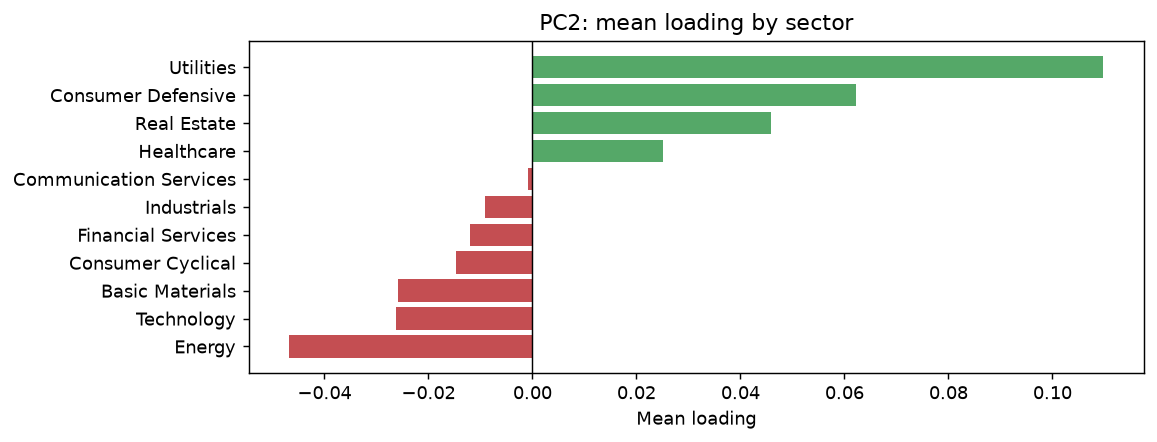

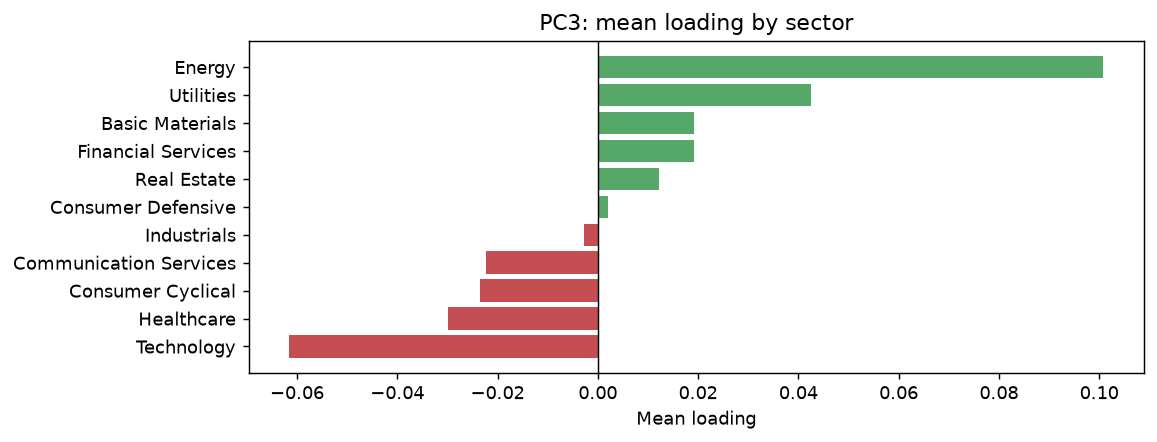

In [26]:
for name in ('PC1', 'PC2', 'PC3'):
    plot_sector_means(eigen.sector_profile(eigen.loadings_frame(eig)[name], sectors),
                      title=f'{name}: mean loading by sector')

## 7. Denoising and detoning

Both procedures rebuild the correlation matrix from its eigenvectors and eigenvalues, altering the
eigenvalues and leaving the eigenvectors untouched.

**Denoising** replaces every eigenvalue that section 3 classified as noise with the average of that
group, then rebuilds the matrix. The sum of the eigenvalues is unchanged by that substitution, and that
sum equals the sum of the diagonal entries, so the rebuilt matrix still carries 1 down its diagonal as a
correlation matrix must. The result is better conditioned than the sample matrix, meaning its smallest
eigenvalue sits further from zero, so inverting it amplifies estimation error less. Nothing classified
as signal is discarded. This is the constant-residual-eigenvalue method of López de Prado.

**Detoning** removes the market component outright. The matrix is rebuilt from the remaining
eigenvector-eigenvalue pairs and rescaled to restore 1 on the diagonal. The result is singular, meaning
at least one of its eigenvalues is exactly zero, and it must never be inverted.

Detoning bears directly on the question this notebook asks. PC1 puts weight on essentially every
security, so the sample correlation matrix largely records how much market exposure each security
carries, and any sector or relative-value structure underneath is masked by it. Section 6 is therefore
repeated on the detoned matrix to test the claim that removing the market component makes sector
structure easier to detect. That claim is the usual argument for detoning, and it is treated here as
something to check rather than as something established.

In [27]:
n_facts = eigen.n_signal_factors(eig.values, q=days_per_stock, sigma2=sigma2_kde)
denoised = eigen.denoise(eig, n_facts=n_facts)
detoned  = eigen.detone(eig, n_market=1)
detoned_eig = eigen.eigen_decompose(pd.DataFrame(detoned, index=eig.names, columns=eig.names))

raw_off = corr.to_numpy()[~np.eye(n_stocks, dtype=bool)]
det_off = detoned[~np.eye(n_stocks, dtype=bool)]
print(f'mean off-diagonal correlation   sample {raw_off.mean():+.4f}, detoned {det_off.mean():+.4f}')
print(f'denoised                        {n_facts} components retained, maximum deviation of the diagonal from 1: {np.abs(np.diag(denoised) - 1).max():.2e}')
print(f'detoned                         smallest eigenvalue {np.linalg.eigvalsh(detoned).min():.2e}, singular by construction and not to be inverted')

mean off-diagonal correlation   sample +0.3254, detoned -0.0023
denoised                        21 components retained, maximum deviation of the diagonal from 1: 2.22e-16
detoned                         smallest eigenvalue -1.65e-15, singular by construction and not to be inverted


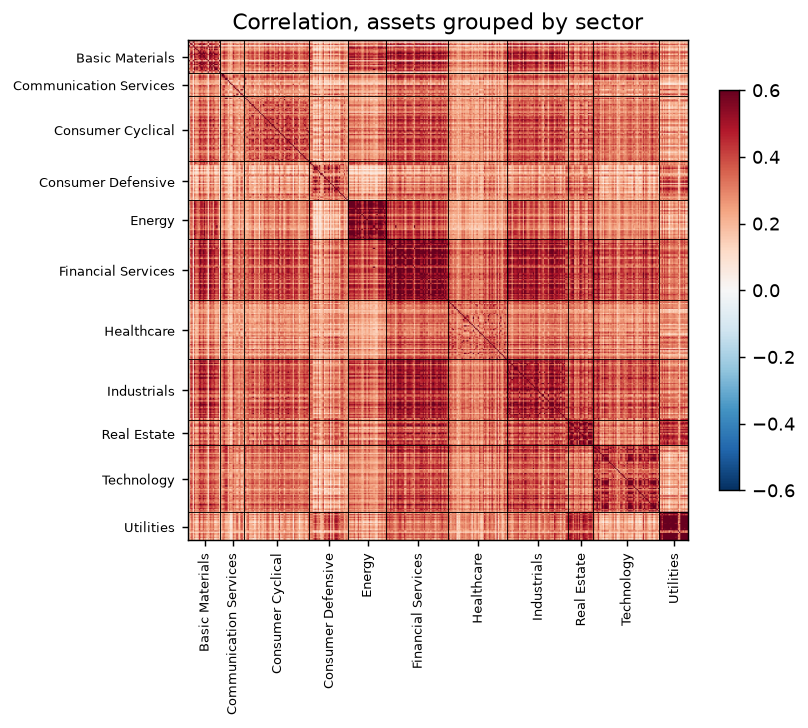

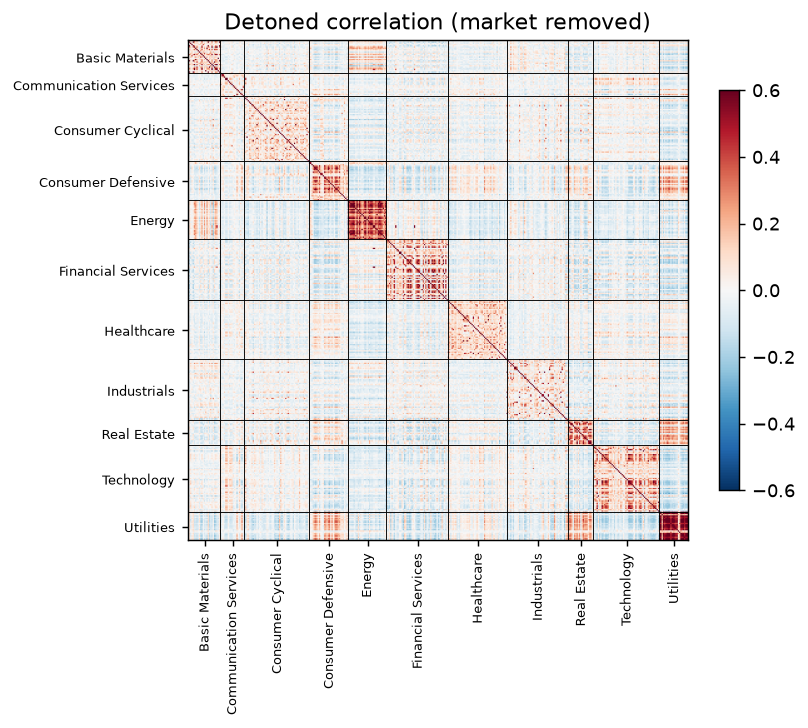

In [28]:
order, boundaries, labels = sector_order(sectors, eig.names)
plot_corr_heatmap(corr.to_numpy(), order=order, boundaries=boundaries, labels=labels,
                  title='Correlation, assets grouped by sector')
plot_corr_heatmap(detoned, order=order, boundaries=boundaries, labels=labels,
                  title='Detoned correlation (market removed)')

In [29]:
# Sector attribution of the leading components, before and after detoning
comparison = []
for i in range(5):
    comparison.append({
        'component': f'PC{i + 1}',
        'eta^2 sample': eigen.sector_eta_squared(eigen.loadings_frame(eig)[f'PC{i + 1}'], sectors),
        'eta^2 detoned': eigen.sector_eta_squared(eigen.loadings_frame(detoned_eig)[f'PC{i + 1}'], sectors),
    })
show_df(pd.DataFrame(comparison).set_index('component'), decimals=4)

,eta2 raw,eta2 detoned
component,,
PC1,0.416,0.5745
PC2,0.6112,0.6373
PC3,0.6681,0.6539
PC4,0.5575,0.5851
PC5,0.6156,0.3086


## 8. Eigenportfolios

A loading multiplies a standardized return, so it is not a position. Dividing each loading by the sample
standard deviation of that security's returns converts the component into a set of holdings that
reproduces it from raw returns.

Those holdings are then scaled so that the sum of their absolute values equals 1. That sum is the gross
exposure, the total capital committed, counting a short position as a commitment rather than as a
negative one. The plain sum of the holdings, in which longs and shorts cancel, is the net exposure.
Fixing gross exposure at 1 puts every component on the same scale for comparison. Net exposure is
reported rather than assumed, because a net exposure near zero is exactly the property that would make
PC2 and the components after it market neutral, meaning unaffected by the market as a whole rising or
falling.

Performance is computed from simple returns rather than log returns. A portfolio's return is the
weighted sum of the simple returns of its holdings. It is not the weighted sum of their log returns, so
using log returns here would give a wrong figure.

The results are in-sample. The weights were estimated on the same sessions over which their performance
is then measured, so the figures describe the decomposition and are not an estimate of what such a
portfolio would have earned.

In [30]:
weights = eigen.eigenportfolios(eig, std.vol, k=5)
simple = panels.returns_panel(closes, kind='simple')

summary = pd.DataFrame({
    'gross': weights.abs().sum(),
    'net': weights.sum(),
    'largest weight': weights.abs().max(),
    'names in top decile': (weights.abs().rank(ascending=False) <= n_stocks / 10).sum(),
})
show_df(summary, decimals=4)

perf = simple.to_numpy() @ weights.to_numpy()
perf = pd.DataFrame(perf, index=simple.index, columns=weights.columns)
show_df(pd.DataFrame({'annualized return': perf.mean() * 252,
                      'annualized volatility': perf.std(ddof=1) * np.sqrt(252),
                      'Sharpe ratio': perf.mean() / perf.std(ddof=1) * np.sqrt(252)}), decimals=4)

,gross,net,largest weight,names in top decile
PC1,1,1,0.005443,40
PC2,1,0.3216,0.01477,40
PC3,1,-0.0231,0.01004,40
PC4,1,0.09465,0.007918,40
PC5,1,-0.05327,0.01014,40


,ann. return,ann. vol,sharpe
PC1,0.1649,0.1731,0.9525
PC2,0.02185,0.07647,0.2857
PC3,-0.03986,0.07092,-0.5621
PC4,0.02574,0.05982,0.4302
PC5,-0.006807,0.04588,-0.1484


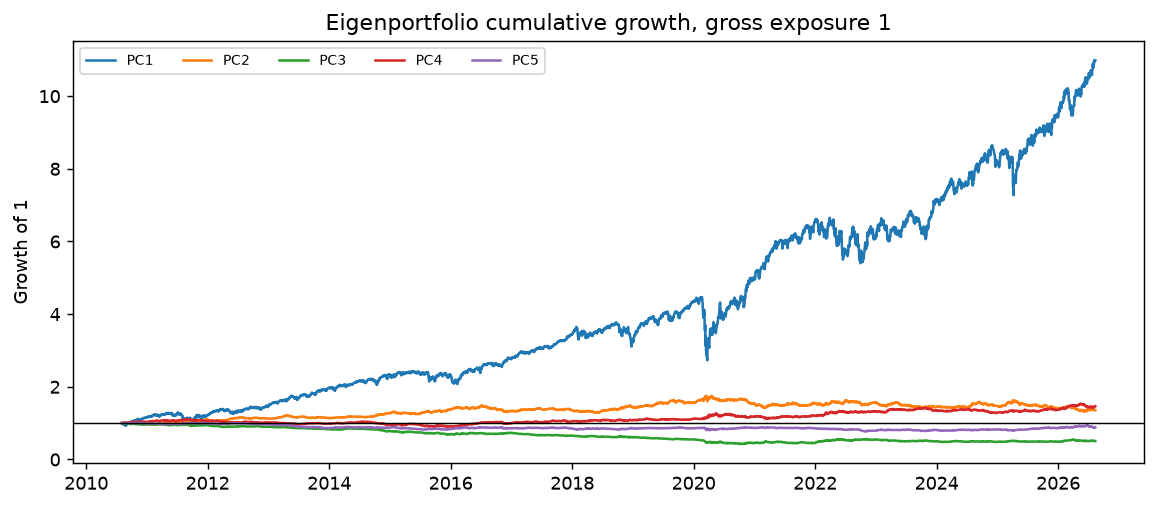

In [31]:
fig, ax = plt.subplots(figsize=(9, 4))
for column in perf.columns:
    ax.plot(perf.index, (1 + perf[column]).cumprod(), lw=1.4, label=column)
ax.axhline(1.0, color='black', lw=0.8)
ax.set_title('Eigenportfolio cumulative growth, gross exposure 1')
ax.set_ylabel('Growth of 1')
ax.legend(ncols=5, fontsize=8)
plt.tight_layout()
plt.show()

## 9. Stability

This section answers the question section 3 leaves open. A component that does not reappear on data that
was not used to compute it is not a factor, whatever its eigenvalue says.

The sessions are split into two halves sharing no dates, and the decomposition is run separately on
each. Two measures of agreement are reported, because they ask different questions.

The first is the absolute cosine. Take the eigenvector for component k from the first half and the
eigenvector for component k from the second half. Both have length 1, so the absolute value of their dot
product is 1 when they point the same way and 0 when they are at right angles. The absolute value is
used because the sign of an eigenvector is arbitrary. This measure asks whether one particular direction
comes back.

The second is subspace similarity. Rather than comparing single eigenvectors, it compares the whole
space spanned by the leading k eigenvectors of each half. The principal angles between two such spaces
come from the singular values of the product of the two eigenvector matrices, and the cosines of those
angles are averaged. This asks whether the k-dimensional space comes back, without requiring the
individual directions inside it to be preserved. It is the right measure when two eigenvalues are nearly
equal, because their eigenvectors can then rotate freely within the plane they share while the plane
itself stays fixed.

The two halves are consecutive in time. A genuine change in the correlation structure between them
therefore cannot be told apart from estimation error by this test alone, and the rolling decomposition
that follows addresses that. Consecutive rolling windows share all but `ROLL_STEP` of their
`ROLL_WINDOW` sessions, an overlap of 1 - ROLL_STEP/ROLL_WINDOW. Their agreement is consequently high
almost by construction and its level says little. Read that series for drops, which mark the points
where the correlation structure changed, rather than for its average.

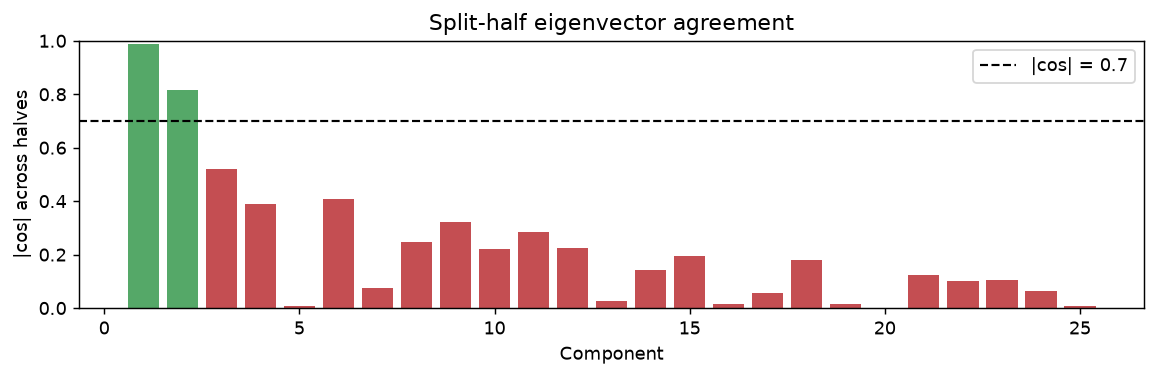

components reproducing at an absolute cosine of 0.7 or above: 2 of 25


,subspace similarity
leading k,
1,0.9885
2,0.903
3,0.7863
5,0.7358
10,0.7355
17,0.7154
25,0.6985


In [32]:
half = len(std.z) // 2
first  = eigen.eigen_decompose(eigen.correlation(std.z.iloc[:half]))
second = eigen.eigen_decompose(eigen.correlation(std.z.iloc[half:]))

similarity = eigen.loading_similarity(first, second, k=25)
plot_stability(similarity)
print(f'components reproducing at an absolute cosine of 0.7 or above: {int((similarity.to_numpy() >= 0.7).sum())} of {len(similarity)}')

show_df(pd.DataFrame([{'leading k': k, 'subspace similarity': eigen.subspace_similarity(first, second, k=k)}
                      for k in (1, 2, 3, 5, 10, 17, 25)]).set_index('leading k'), decimals=4)

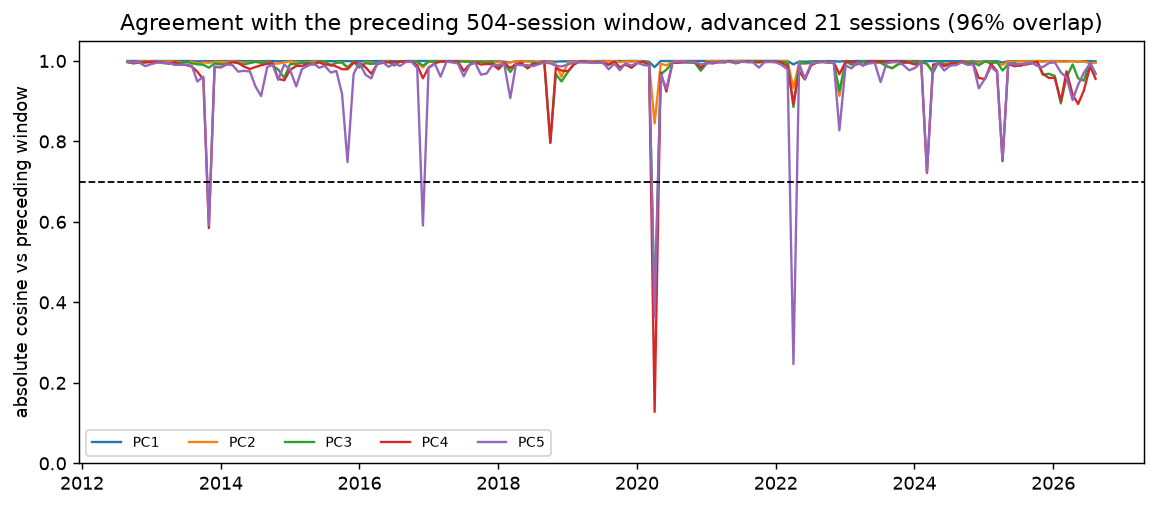

,PC1,PC2,PC3,PC4,PC5
mean,0.9994,0.9947,0.9854,0.9747,0.9658
min,0.9848,0.8446,0.384,0.128,0.2467
max,1,0.9999,0.9997,0.9993,0.9988


In [33]:
windows = panels.rolling_windows(calendar, window=ROLL_WINDOW, step=ROLL_STEP)
fits = []
for start, stop in windows:
    chunk = std.z.loc[start:stop]
    fits.append((stop, eigen.eigen_decompose(eigen.correlation(chunk))))

rolling = pd.DataFrame(
    [eigen.loading_similarity(fits[i - 1][1], fits[i][1], k=5).to_numpy() for i in range(1, len(fits))],
    index=[stop for stop, _ in fits[1:]], columns=[f'PC{i + 1}' for i in range(5)])

fig, ax = plt.subplots(figsize=(9, 4))
for column in rolling.columns:
    ax.plot(rolling.index, rolling[column], lw=1.3, label=column)
ax.axhline(0.7, color='black', ls='--', lw=1.0)
ax.set_ylim(0, 1.05)
ax.set_title(f'Agreement with the preceding {ROLL_WINDOW}-session window, advanced {ROLL_STEP} sessions '
             f'({1 - ROLL_STEP / ROLL_WINDOW:.0%} overlap)')
ax.set_ylabel('absolute cosine vs preceding window')
ax.legend(ncols=5, fontsize=8)
plt.tight_layout()
plt.show()
show_df(rolling.describe().loc[['mean', 'min', 'max']], decimals=4)

## 10. Findings

Every figure below came from one run and does not survive a change to the parameter cell. That run used
`UNIVERSE = None`, `RANK_BY = 'liquidity'`, `N_TOP = 400`, `RETURN_KIND = 'log'` and
`BENCHMARK = '^NDQ'`, over 1,260 trading sessions ending in 2026-08. The parameter cell now holds
different values, so these results have to be regenerated before they are quoted anywhere.

**PC1 is a market factor, and the evidence is not ambiguous.** It accounts for 26.7% of the total
variance, against 6.7% for PC2. All 400 of its loadings carry the same sign, so its homogeneity is
1.0000 against the 0.5 that an even split would give. Its time series correlates at +0.996 with the
equal-weighted average of the standardized returns, and at +0.854 with `^NDQ`, the Nasdaq Composite
index. Split into two halves that share no dates, its eigenvector comes back at an absolute cosine of
0.97, where 1.0 is a perfect match. Its loadings run from 0.0116 to 0.0763, a spread of roughly six to
one, and that spread is the cross-section of market exposure.

**PC2 has the shape of a spread but barely reproduces.** Its homogeneity is 0.53, meaning the loadings
divide almost evenly between positive and negative, which is what a long-short position looks like. It
accounts for 6.7% of the variance. Across the two halves it comes back at an absolute cosine of 0.68,
under the 0.7 threshold used here as the bar for calling a component real.

**No individual component past PC2 reproduces at all.** Of the leading 25 components, exactly one
reaches an absolute cosine of 0.7 across the two halves. PC3 comes back at 0.23, which is closer to two
unrelated directions than to a match. The individual eigenvectors past PC2 are therefore not identifiable
on this sample.

The leading three-dimensional subspace does better, coming back at 0.76 while PC2 and PC3 individually
manage 0.68 and 0.23. That gap is what nearly equal eigenvalues predict. The subspace holds still while
the directions inside it rotate, so measuring the directions one at a time understates what is stable.

**The count of components carrying signal depends entirely on which method is used, so no single count
should be trusted.** The four criteria of section 3 return 17, between 22 and 35, 60, and 113. The 17
comes from Marcenko-Pastur at the fitted sigma^2, and parallel analysis independently agrees with it to
three decimal places. The range of 22 to 35 is the same Marcenko-Pastur fit at other kernel bandwidths.
The 60 is the Kaiser criterion and the 113 is the bandwidth-free fixed point. They disagree because the
eigenvalue bulk is not the shape Marcenko-Pastur assumes, as section 3 sets out. Section 9 gives the
answer that can be acted on, and it says one component, possibly two.

**Sector structure runs through every component rather than appearing only in the later ones.** Eta
squared falls between 0.29 and 0.51 for each of the leading ten components, against a permutation null
of about 0.045. Every one of the ten therefore clears chance by a wide margin. PC1 is among them, which
is the surprise: its loadings all carry the same sign, but their sizes vary systematically by sector, so
market exposure is itself partly a sector characteristic. The conventional order of market, then spread,
then sector does not hold cleanly here.

**Detoning changes the matrix as intended but does not make sector structure easier to see.** The mean
correlation between distinct securities falls from +0.249 to -0.001, so the market component is
genuinely gone. Eta squared then rises for PC1 and PC4 but falls for PC2, PC3 and PC5. The claim tested
in section 7, that removing the market component would make sector structure more visible, is therefore
not supported.

### Limitations

- The cross-section consists of survivors, and that is imposed by the database rather than by the panel
  construction here. The coverage cell in section 2 reports how many price series stop before the window
  closes and when they stop. Series stopping only in the final months are ordinary recent delistings;
  their absence from the earlier history would mean no company delisted or acquired during the period is
  represented at all. The distortion grows with the length of the window.
- The results come from one universe and one window. Both are parameters at the top of the notebook, and
  nothing established here shows they are the right choices.
- The eigenportfolio performance in section 8 is in-sample, measured over the same sessions on which the
  weights were estimated.

### Further work

- Whether PC2 reaches 0.7 on a different universe or a different window. This is the cheapest of these
  questions to settle.
- How the stability measures behave as N grows. Adding securities while holding the number of sessions
  fixed should degrade them, and the rate at which it does so is informative.
- Decomposing sector-neutralized returns, given that sector structure turned out to run through every
  component rather than being confined to the later ones.